# DS5110 Homework 2: tidy, reshape, join

Three files from three systems → one tidy, analysis-ready table.
Every step below runs in order, top to bottom. The reasoning behind each decision is in `WRITEUP.md`.

| File | What it holds |
| --- | --- |
| `data/company_quarterly_revenue_raw.csv` | revenue per company per quarter |
| `data/orders.csv` | one line per customer order |
| `data/shipments.csv` | tracking numbers for shipped packages |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

DATA = Path("data")
FIGURES = Path("figures")
OUTPUT = Path("output")
FIGURES.mkdir(exist_ok=True)
OUTPUT.mkdir(exist_ok=True)

## Step 0: Descriptive analysis (before changing anything)

Load each file exactly as it comes, report its shape, and look at the first rows.

In [2]:
revenue_raw = pd.read_csv(DATA / "company_quarterly_revenue_raw.csv")
orders = pd.read_csv(DATA / "orders.csv")
shipments = pd.read_csv(DATA / "shipments.csv")

for name, df in [("revenue_raw", revenue_raw), ("orders", orders), ("shipments", shipments)]:
    print(f"{name:12} {df.shape[0]:>3} rows x {df.shape[1]:>2} columns   missing values: {df.isna().sum().sum()}")

revenue_raw    5 rows x 13 columns   missing values: 0
orders        20 rows x  5 columns   missing values: 0
shipments     35 rows x  2 columns   missing values: 0


In [3]:
revenue_raw.head()

,company,2023-Q1,2023-Q2,2023-Q3,2023-Q4,2024-Q1,2024-Q2,2024-Q3,2024-Q4,2025-Q1,2025-Q2,2025-Q3,2025-Q4
0,Acme,13.5,14.1,15.9,16.8,15.6,16.7,18.4,17.1,18.6,19.9,20.5,20.3
1,Globex,10.3,8.7,9.4,10.7,13.5,12.0,11.6,11.6,14.0,13.8,15.9,14.0
2,Initech,16.9,15.7,16.7,16.8,17.1,17.9,18.1,18.4,18.6,17.9,20.2,22.3
3,Soylent,10.8,12.9,14.9,15.4,15.5,19.4,20.1,22.1,23.0,22.9,22.0,23.6
4,Umbrella,8.1,6.1,7.7,8.7,9.6,8.7,11.7,10.4,9.8,11.8,12.4,14.3


In [4]:
orders.head()

,order_id,customer_id,amount,company,quarter
0,O1000,C106,26,Umbrella,2024-Q4
1,O1001,C105,48,Umbrella,2023-Q3
2,O1002,C103,155,Globex,2025-Q2
3,O1003,C100,38,Acme,2023-Q4
4,O1004,C103,136,Globex,2023-Q3


In [5]:
shipments.head(8)

,order_id,tracking
0,O1000,O1000-1
1,O1001,O1001-1
2,O1001,O1001-2
3,O1002,O1002-1
4,O1003,O1003-1
5,O1003,O1003-2
6,O1004,O1004-1
7,O1004,O1004-2


To judge tidiness we first need to know **what one row represents** in each file.

In [6]:
print("revenue_raw: one row per company?   ", revenue_raw["company"].is_unique)
print("orders:      one row per order?     ", orders["order_id"].is_unique)
print("shipments:   one row per tracking #?", shipments["tracking"].is_unique)

revenue_raw: one row per company?    True
orders:      one row per order?      True
shipments:   one row per tracking #? True


### Is each file tidy?

The three rules (Wickham): **(1)** every variable is a column, **(2)** every observation is a row, **(3)** every value is a cell.

**`company_quarterly_revenue_raw.csv` (5 × 13): not tidy.**
- Rule 1 fails. *Quarter* is a variable, but its values (`2023-Q1` … `2025-Q4`) are stored as 12 column **names** instead of in one `quarter` column. *Revenue*, also one variable, is spread across those 12 columns.
- Rule 2 fails. One observation is "one company's revenue in one quarter". Each row packs 12 of them.
- Rule 3 holds. Every cell holds a single number.

**`orders.csv` (20 × 5): tidy.**
- Rule 1: each column is one variable (`order_id`, `customer_id`, `amount`, `company`, `quarter`).
- Rule 2: each row is one order (`order_id` is unique, checked above).
- Rule 3: one value per cell. (`quarter` like `2023-Q1` is one variable, the period, written the same way as the revenue headers. That is what lets us join the two later.)

**`shipments.csv` (35 × 2): tidy, for its own unit.**
- Rule 2: each row is one **shipment** (one package; `tracking` is unique), not one order. `order_id` repeats, so this table is at a finer level than `orders`.
- Rules 1 and 3: two variables, one value per cell. `tracking` repeats the order id inside it (`O1001-2`), but it is an ID label, a single value.

### Exploratory charts of the raw data

Each panel plots a file in the shape it arrived. The revenue panel is drawn by a function so Step 5 can redraw it.

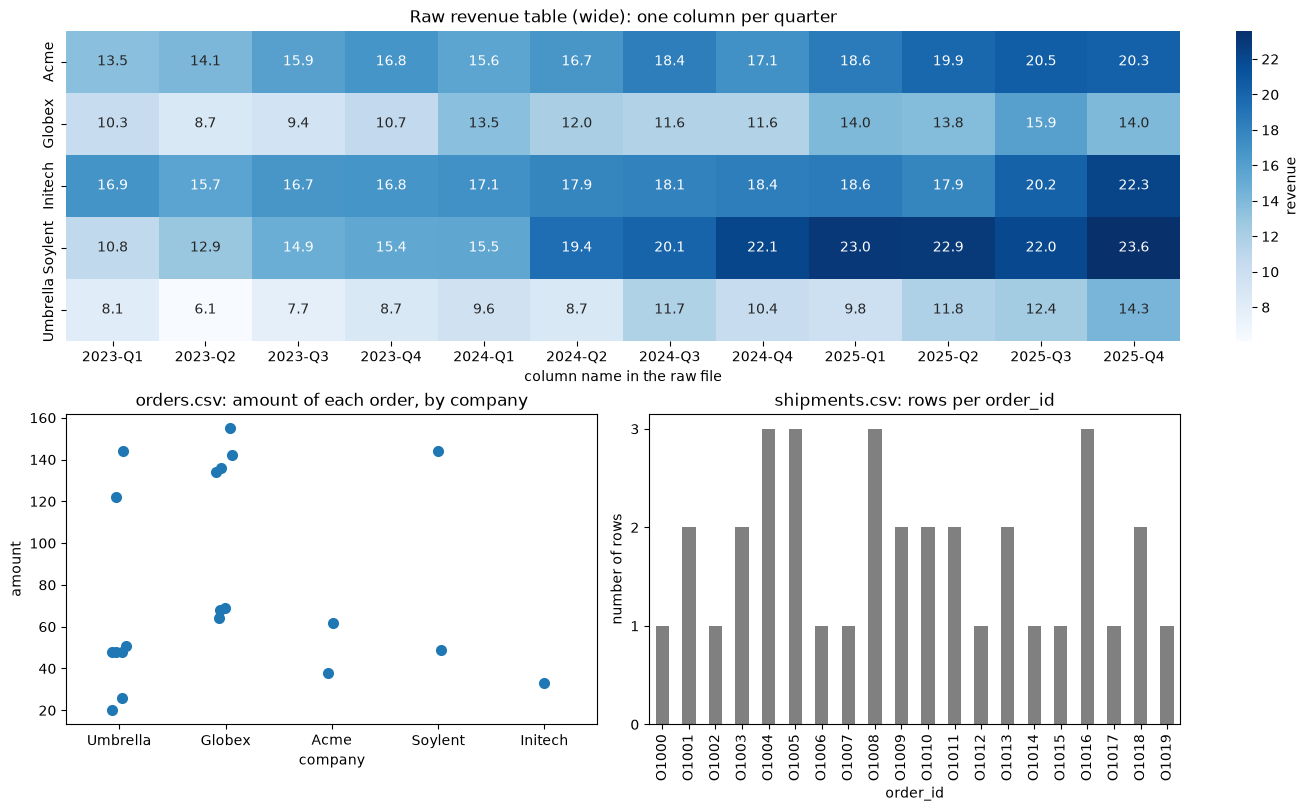

In [7]:
def draw_raw_revenue(ax):
    """Heatmap of the raw wide revenue table, exactly as it comes: companies x quarter columns."""
    sns.heatmap(revenue_raw.set_index("company"), annot=True, fmt=".1f", cmap="Blues",
                cbar_kws={"label": "revenue"}, ax=ax)
    ax.set_title("Raw revenue table (wide): one column per quarter")
    ax.set_xlabel("column name in the raw file")
    ax.set_ylabel("")


fig, axes = plt.subplot_mosaic([["rev", "rev"], ["ord", "ship"]], figsize=(13, 8), layout="constrained")

draw_raw_revenue(axes["rev"])

sns.stripplot(data=orders, x="company", y="amount", size=8, ax=axes["ord"])
axes["ord"].set_title("orders.csv: amount of each order, by company")

shipments["order_id"].value_counts().sort_index().plot.bar(ax=axes["ship"], color="gray")
axes["ship"].set_title("shipments.csv: rows per order_id")
axes["ship"].set_ylabel("number of rows")
axes["ship"].set_yticks([0, 1, 2, 3])

fig.savefig(FIGURES / "step0_raw_data.png", dpi=150)
plt.show()

What the raw charts already show:
- **Revenue:** every company grows over time, but you read it across a row of column headers, not along an axis.
- **Orders:** Globex and Soylent have the largest orders; Initech has just one.
- **Shipments:** many `order_id`s have 2 or 3 rows. This is the first hint that `order_id` is **not** a unique key in `shipments`.

## Step 1: Revenue table, wide → long

The revenue table is **wide**: one row per company, one column per quarter.
`melt` moves the 12 quarter column names down into a single `quarter` column, so each row becomes one (company, quarter) observation.

In [8]:
revenue = revenue_raw.melt(id_vars="company", var_name="quarter", value_name="revenue")
revenue = revenue.sort_values(["company", "quarter"]).reset_index(drop=True)

n_companies = revenue_raw.shape[0]
n_quarters = revenue_raw.shape[1] - 1  # every column except "company"
print("expected rows:", n_companies, "x", n_quarters, "=", n_companies * n_quarters)
print("actual shape: ", revenue.shape)

assert len(revenue) == n_companies * n_quarters
assert not revenue.duplicated(subset=["company", "quarter"]).any()  # one row per (company, quarter)
revenue.head(6)

expected rows: 5 x 12 = 60
actual shape:  (60, 3)


,company,quarter,revenue
0,Acme,2023-Q1,13.5
1,Acme,2023-Q2,14.1
2,Acme,2023-Q3,15.9
3,Acme,2023-Q4,16.8
4,Acme,2024-Q1,15.6
5,Acme,2024-Q2,16.7


Same 60 numbers, new layout: `company` and `quarter` identify each row, `revenue` is the measured value. All three rules now hold.

## Step 2: Is `order_id` really a unique key?

Check before joining, never after.

In [9]:
print(f"orders:    {len(orders)} rows, {orders['order_id'].nunique()} distinct order_id, unique: {orders['order_id'].is_unique}")
print(f"shipments: {len(shipments)} rows, {shipments['order_id'].nunique()} distinct order_id, unique: {shipments['order_id'].is_unique}")

orders:    20 rows, 20 distinct order_id, unique: True
shipments: 35 rows, 20 distinct order_id, unique: False


In [10]:
# How many orders have 1, 2 or 3 shipment rows?
shipments_per_order = shipments["order_id"].value_counts()
shipments_per_order.value_counts().sort_index().rename_axis("shipment rows").rename("orders")

shipment rows
1    9
2    7
3    4
Name: orders, dtype: int64

In [11]:
# Do the keys match up? Unmatched keys would change the row count too.
print("shipments with no matching order:", set(shipments["order_id"]) - set(orders["order_id"]))
print("orders with no shipment:         ", set(orders["order_id"]) - set(shipments["order_id"]))

shipments with no matching order: set()
orders with no shipment:          set()


**What this means for the join:** `order_id` is unique in `orders` but repeats in `shipments`, so the join is **one-to-many (1:many)**.
Each order row will be copied once per matching shipment.

**Prediction:** for each order, rows after the join = 1 × (its shipment count). Every order has at least one shipment, so the join should return exactly as many rows as `shipments`.

In [12]:
predicted_rows = (1 * shipments_per_order).sum()
print("predicted rows after joining orders to shipments:", predicted_rows)

predicted rows after joining orders to shipments: 35


## Step 3: Join orders and shipments, then mean amount per customer

`validate="one_to_many"` makes pandas raise an error if `order_id` is ever not unique on the orders side.
A left join keeps every order even if it had no shipment (none here, but the code should not silently drop one).

In [13]:
orders_shipments = orders.merge(shipments, on="order_id", how="left", validate="one_to_many")

print("orders:", len(orders), "rows -> joined:", len(orders_shipments), "rows (predicted", predicted_rows, ")")
assert len(orders_shipments) == predicted_rows
orders_shipments.head(6)

orders: 20 rows -> joined: 35 rows (predicted 35 )


,order_id,customer_id,amount,company,quarter,tracking
0,O1000,C106,26,Umbrella,2024-Q4,O1000-1
1,O1001,C105,48,Umbrella,2023-Q3,O1001-1
2,O1001,C105,48,Umbrella,2023-Q3,O1001-2
3,O1002,C103,155,Globex,2025-Q2,O1002-1
4,O1003,C100,38,Acme,2023-Q4,O1003-1
5,O1003,C100,38,Acme,2023-Q4,O1003-2


Notice order `O1001` now appears twice with `amount = 48` both times. The amount was **copied**, not doubled in reality.

In [14]:
mean_on_joined = orders_shipments.groupby("customer_id")["amount"].mean()   # (a)
mean_on_orders = orders.groupby("customer_id")["amount"].mean()             # (b)

comparison = pd.DataFrame({
    "orders": orders.groupby("customer_id").size(),
    "rows_in_join": orders_shipments.groupby("customer_id").size(),
    "(a) mean on joined": mean_on_joined.round(2),
    "(b) mean on orders": mean_on_orders.round(2),
})
comparison["difference"] = (comparison["(a) mean on joined"] - comparison["(b) mean on orders"]).round(2)
comparison

,orders,rows_in_join,(a) mean on joined,(b) mean on orders,difference
customer_id,,,,,
C100,1,2,38.00,38.00,0.00
C101,1,1,62.00,62.00,0.00
C102,2,2,105.00,105.00,0.00
C103,5,8,112.38,111.60,0.78
C104,1,1,33.00,33.00,0.00
C105,4,8,67.62,67.25,0.37
C106,4,8,62.25,59.50,2.75
C107,2,5,106.00,96.50,9.50


In [15]:
# Worked example: customer C107, the largest gap
orders_shipments.loc[orders_shipments["customer_id"] == "C107", ["order_id", "amount", "tracking"]]

,order_id,amount,tracking
9,O1005,144,O1005-1
10,O1005,144,O1005-2
11,O1005,144,O1005-3
19,O1010,49,O1010-1
20,O1010,49,O1010-2


**Which one is correct? (b), the mean on `orders` alone.**

`amount` belongs to the **order**, not to the shipment. The join copies each order's amount once per shipment, so an order shipped in 3 boxes is counted 3 times in the average.
C107 placed two orders: 144 (3 shipments) and 49 (2 shipments).
- (a) joined: (144 + 144 + 144 + 49 + 49) / 5 = **106.0**, biased toward the order that shipped in more boxes
- (b) orders: (144 + 49) / 2 = **96.5**, each order counted once

The numbers only agree for customers whose orders all had one shipment, which is why the bug is easy to miss.

### Joining correctly

The fix is to bring `shipments` **up to the order level first** (one row per order, with a count of shipments), then join. That join is one-to-one, so the order count cannot change.

In [16]:
shipment_counts = shipments.groupby("order_id").size().reset_index(name="n_shipments")

orders_clean = orders.merge(shipment_counts, on="order_id", how="left", validate="one_to_one")
orders_clean["n_shipments"] = orders_clean["n_shipments"].fillna(0).astype(int)  # an order with no shipment gets 0

assert len(orders_clean) == len(orders)                         # 1:1 -> row count unchanged
assert orders_clean["n_shipments"].sum() == len(shipments)      # no shipment lost
assert orders_clean.groupby("customer_id")["amount"].mean().equals(mean_on_orders)  # matches (b)
print(orders_clean.shape)
orders_clean.head()

(20, 6)


,order_id,customer_id,amount,company,quarter,n_shipments
0,O1000,C106,26,Umbrella,2024-Q4,1
1,O1001,C105,48,Umbrella,2023-Q3,2
2,O1002,C103,155,Globex,2025-Q2,1
3,O1003,C100,38,Acme,2023-Q4,2
4,O1004,C103,136,Globex,2023-Q3,3


## Step 4: One analysis-ready table

Unit of observation: **one order**. Each order gets the revenue of its company in the quarter it was placed.

Key check first: in `revenue`, (company, quarter) is unique (asserted in Step 1). In `orders_clean` it repeats (a company can have several orders in one quarter). So this join is **many-to-one**, and the row count should stay at 20.

In [17]:
print("orders sharing a (company, quarter) with another order:",
      orders_clean.duplicated(subset=["company", "quarter"], keep=False).sum())

final = orders_clean.merge(revenue, on=["company", "quarter"], how="left", validate="many_to_one")

assert len(final) == len(orders_clean)        # many:1 -> row count unchanged
assert final["revenue"].notna().all()         # every order found its (company, quarter) revenue

orders sharing a (company, quarter) with another order: 8


In [18]:
final = (
    final
    .rename(columns={"amount": "order_amount", "revenue": "company_quarter_revenue"})
    [["order_id", "customer_id", "company", "quarter", "order_amount", "n_shipments", "company_quarter_revenue"]]
    .sort_values("order_id")
    .reset_index(drop=True)
)

# Tidy checks
assert final["order_id"].is_unique                      # one row per order
assert final.notna().all().all()                        # no gaps
assert not final.columns.str.startswith("Unnamed").any()  # no leftover index columns

final.to_csv(OUTPUT / "orders_analysis_ready.csv", index=False)
print(final.shape)
final

(20, 7)


,order_id,customer_id,company,quarter,order_amount,n_shipments,company_quarter_revenue
0,O1000,C106,Umbrella,2024-Q4,26,1,10.4
1,O1001,C105,Umbrella,2023-Q3,48,2,7.7
2,O1002,C103,Globex,2025-Q2,155,1,13.8
3,O1003,C100,Acme,2023-Q4,38,2,16.8
4,O1004,C103,Globex,2023-Q3,136,3,9.4
5,O1005,C107,Soylent,2023-Q4,144,3,15.4
6,O1006,C101,Acme,2024-Q3,62,1,18.4
7,O1007,C103,Globex,2025-Q2,64,1,13.8
8,O1008,C106,Umbrella,2025-Q2,48,3,11.8
9,O1009,C105,Umbrella,2023-Q2,122,2,6.1


In [19]:
final.dtypes

order_id                       str
customer_id                    str
company                        str
quarter                        str
order_amount                 int64
n_shipments                  int64
company_quarter_revenue    float64
dtype: object

**Column guide**

| Column | Meaning | Source |
| --- | --- | --- |
| `order_id` | order identifier (unique) | orders |
| `customer_id` | who placed the order | orders |
| `company` | company the order was placed with | orders |
| `quarter` | quarter the order was placed, `YYYY-Qn` | orders |
| `order_amount` | value of the order | orders |
| `n_shipments` | number of packages the order shipped in | shipments, counted per order |
| `company_quarter_revenue` | that company's total revenue in that quarter (units not given in the source) | revenue, melted |

**Caution for whoever uses this table:** `company_quarter_revenue` repeats when a company has several orders in the same quarter. Never sum it down this table; use the long `revenue` table for revenue totals.

## Step 5: A chart from the final table, next to the raw chart

The new chart puts three sources on one plot: revenue on x (needed the melt), order amount on y (orders), and point size = number of shipments (needed counting shipments per order). With the final table each one is just a column name.

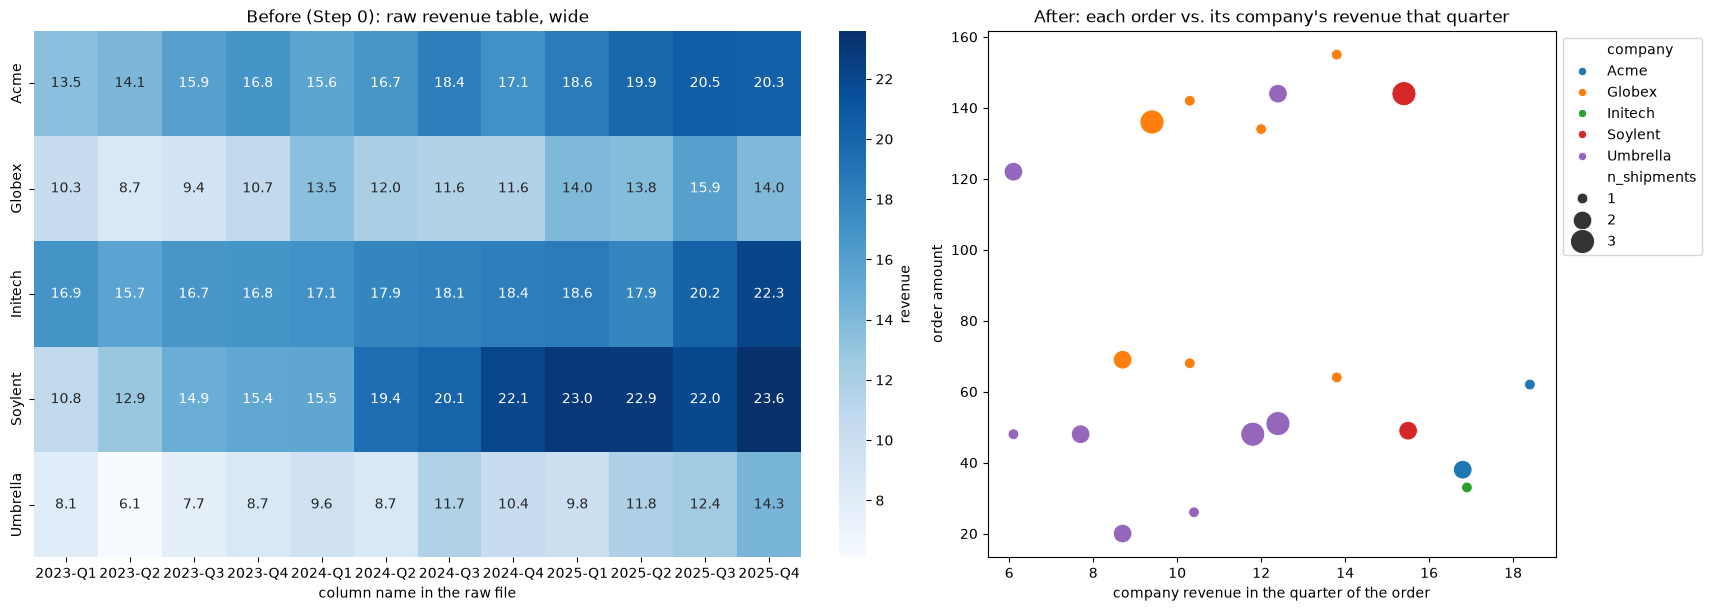

In [20]:
fig, (ax_raw, ax_new) = plt.subplots(1, 2, figsize=(17, 6), layout="constrained",
                                     gridspec_kw={"width_ratios": [1.35, 1]})

draw_raw_revenue(ax_raw)
ax_raw.set_title("Before (Step 0): raw revenue table, wide")

sns.scatterplot(data=final, x="company_quarter_revenue", y="order_amount",
                hue="company", hue_order=sorted(final["company"].unique()), size="n_shipments", sizes=(60, 300), ax=ax_new)
ax_new.set_title("After: each order vs. its company's revenue that quarter")
ax_new.set_xlabel("company revenue in the quarter of the order")
ax_new.set_ylabel("order amount")
ax_new.legend(loc="upper left", bbox_to_anchor=(1, 1))

fig.savefig(FIGURES / "step5_before_after.png", dpi=150)
plt.show()

**What got easier:** in the raw files, revenue for a given order's quarter was hidden in a column *name*, and the number of shipments was spread across several rows of another file. Getting both next to an order meant looking up a column by name for each row and counting rows by hand.
After tidying and joining, every visual channel (x, y, colour, size) maps to exactly one column of one table, so the whole chart is a single `scatterplot` call, and no order is counted more than once.